# EP04｜AI 畫圖原理：怎麼從一片雜訊畫出一張圖？擴散模型

像素腦底加！這是影片裡從零訓練的「超小擴散模型」，按上方的 **執行階段 → 全部執行**（或每格按 ▶️）就能自己跑一遍。
不用顯示卡：訓練在一般 CPU 上大約 1 到 3 分鐘（影片裡的電腦約 1.5 分鐘）。

我們會：
1. 把一張貓咪照片一步一步加雜訊（前向過程）
2. 用 1797 張 8 × 8 的手寫數字，訓練一個「猜雜訊」的小模型
3. 讓它從一片雜訊畫出數字、指定畫 7、試試隨機種子，最後故意做錯一次

⚠️ 這是教學用的小模型，原理和 DDPM（Ho 等人，2020）一樣，但規模比真正的生圖模型小非常多。
不同電腦、不同版本的 PyTorch 算出來的數字可能有一點點不同。

📺 影片：[youtube.com/@pixelbraintw](https://www.youtube.com/@pixelbraintw)

## 0. 準備：載入套件、下載一張貓咪照片（CC0 授權，作者 AdinaVoicu，Wikimedia Commons）

In [1]:
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression

torch.manual_seed(0)
if not os.path.exists("cat.png"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/pixelbraintw/pixelbrain-code/main/ep04-diffusion/cat.png", "cat.png")

def show_digits(x, cols=8, title=None):
    """把很多張 8 × 8 的數字（-1 到 1）排成一張大圖"""
    x = x.clamp(-1, 1).reshape(-1, 8, 8)
    rows = (len(x) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.2, rows * 1.2))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, im in zip(np.atleast_1d(axes).ravel(), x):
        ax.imshow(im, cmap="gray", vmin=-1, vmax=1)
    if title: fig.suptitle(title)
    plt.show()

## 1. 一步一步加雜訊

照 DDPM 論文的設定：一共 1000 步，每一步加的雜訊（beta）從 0.0001 慢慢增加到 0.02。
`abar` 是 (1 - beta) 一路乘下來，`abar.sqrt()` 代表「原圖還剩多少」。
很多次小的高斯雜訊加起來還是一個高斯雜訊，所以 `add_noise` 一行就能直接算出第 t 步的樣子。

In [2]:
T = 1000
beta = torch.linspace(1e-4, 0.02, T)
abar = torch.cumprod(1 - beta, dim=0)

def add_noise(x0, t, eps):
    return abar[t].sqrt() * x0 + (1 - abar[t]).sqrt() * eps

print(abar[[0, 100, 250, 500, 999]].sqrt())

tensor([0.9999, 0.9461, 0.7221, 0.2789, 0.0064])


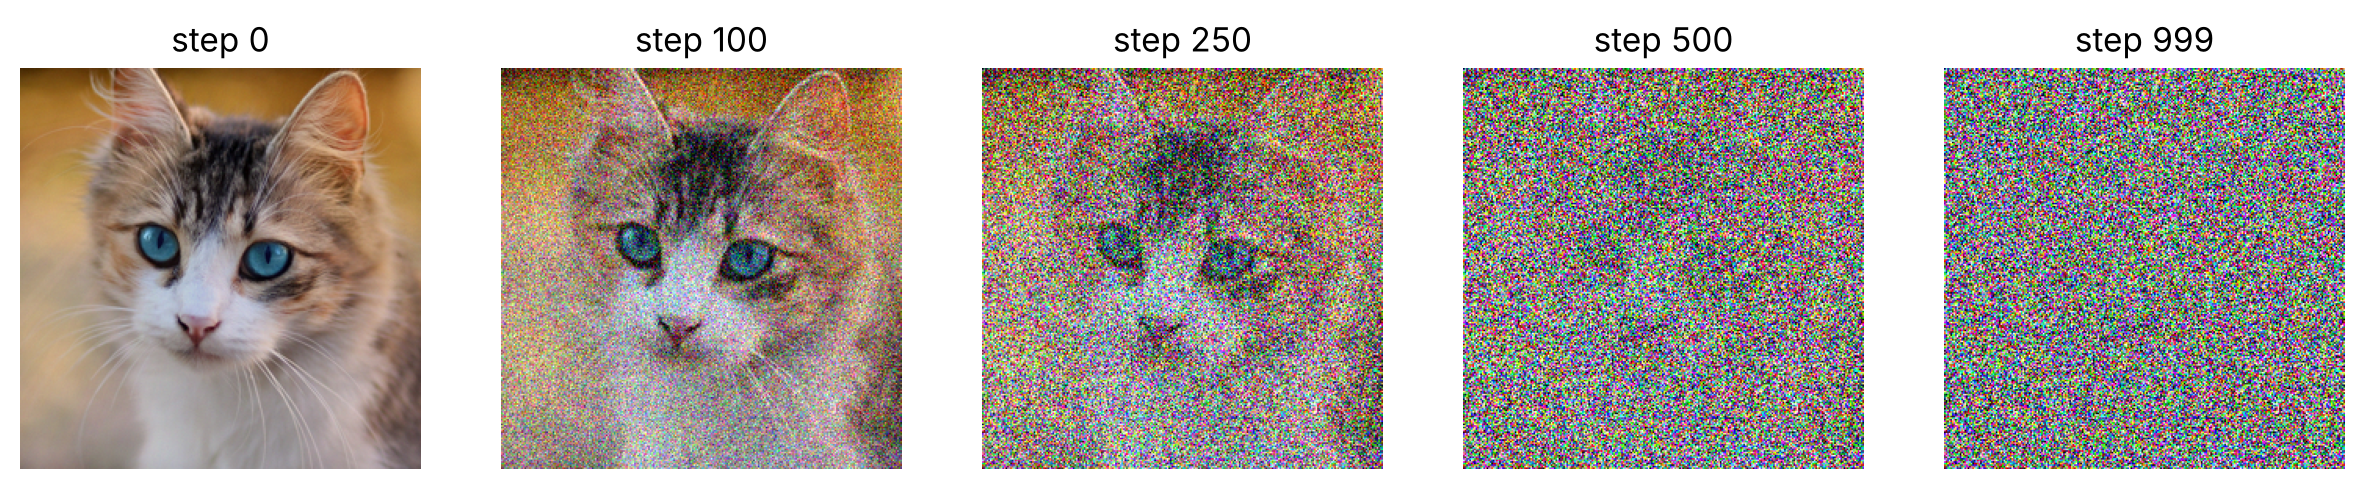

In [3]:
cat = torch.tensor(np.array(Image.open("cat.png").convert("RGB").resize((256, 256))) / 127.5 - 1, dtype=torch.float32)
eps_cat = torch.randn_like(cat)
steps = [0, 100, 250, 500, 999]
fig, axes = plt.subplots(1, len(steps), figsize=(15, 3.4))
for ax, t in zip(axes, steps):
    ax.imshow(((add_noise(cat, t, eps_cat).clamp(-1, 1) + 1) / 2).numpy())
    ax.set_title(f"step {t}"); ax.axis("off")
plt.show()

## 2. 訓練資料：1797 張 8 × 8 的手寫數字

scikit-learn 內建的資料，亮度是 0 到 16。我們換成 -1 到 1，跟雜訊在同一個大小範圍，模型比較好學。

In [4]:
digits = load_digits()
X = torch.tensor(digits.images / 16 * 2 - 1, dtype=torch.float32).reshape(-1, 64)
y = torch.tensor(digits.target)
print(X.shape)

torch.Size([1797, 64])


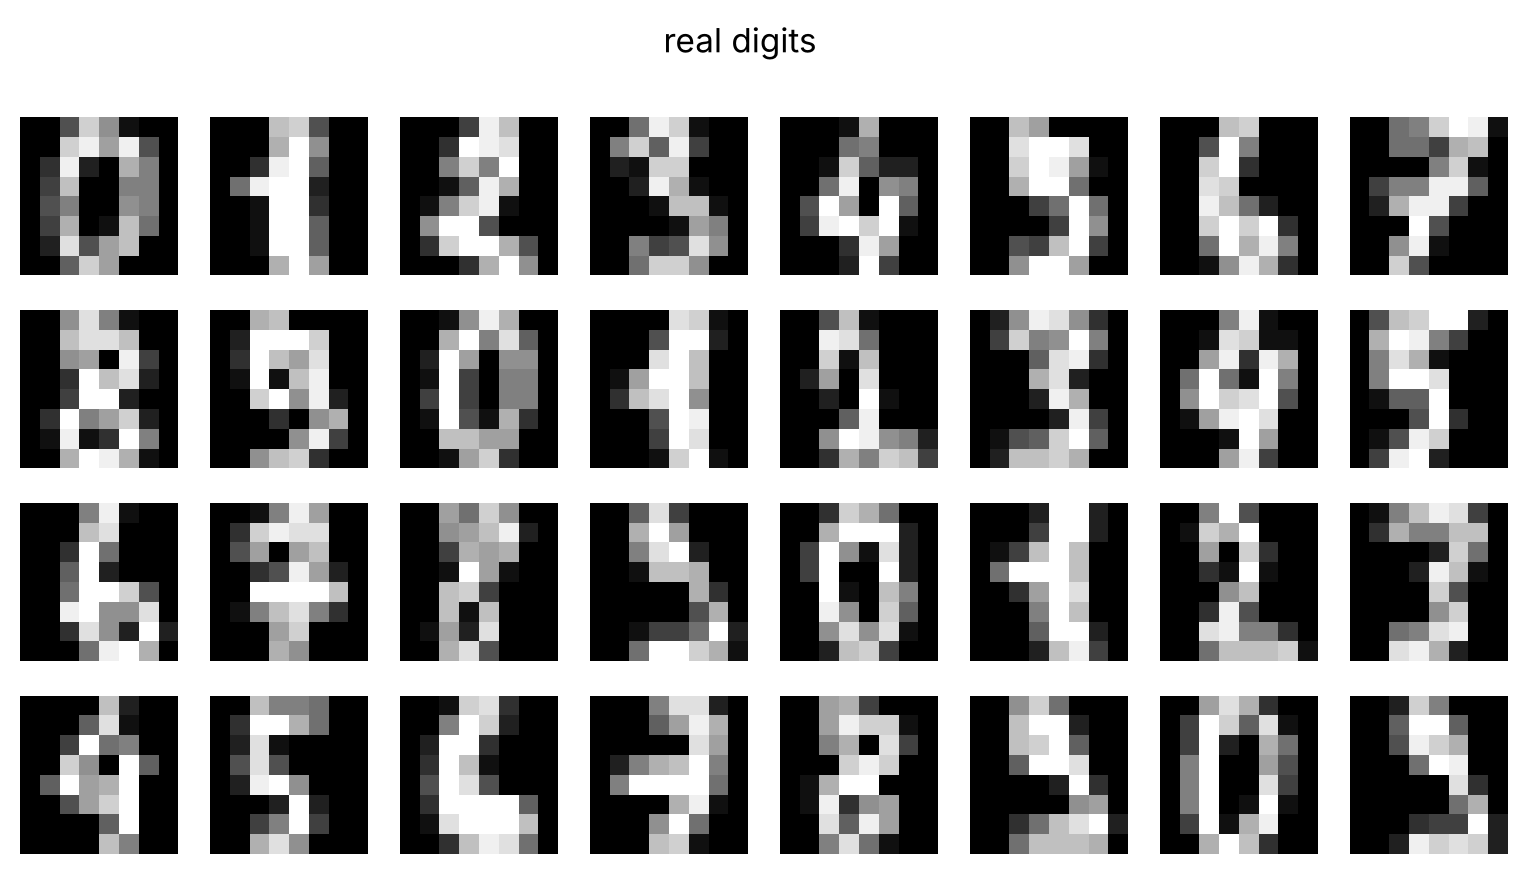

In [5]:
show_digits(X[:32], title="real digits")

## 3. 去雜訊模型

三個輸入：有雜訊的圖（64 個數字）、現在是第幾步、要畫哪個數字（第 10 號代表「不指定」），
接在一起經過三層神經網路，輸出 64 個數字，就是它猜的雜訊。

In [6]:
class Denoiser(nn.Module):
    def __init__(self):
        super().__init__()
        self.time = nn.Embedding(T, 64)    # 現在是第幾步
        self.label = nn.Embedding(11, 64)  # 要畫的數字，10 代表「不指定」
        self.net = nn.Sequential(nn.Linear(64 * 3, 512), nn.SiLU(),
                                 nn.Linear(512, 512), nn.SiLU(), nn.Linear(512, 64))

    def forward(self, x, t, label):
        return self.net(torch.cat([x, self.time(t), self.label(label)], dim=1))

model = Denoiser()
print(sum(p.numel() for p in model.parameters()))

459008


## 4. 訓練：猜出加進去的雜訊

每一輪抽 256 張圖，每張隨便選一個步數、加上隨機雜訊，叫模型猜雜訊；有 10% 的機會把要畫的數字藏起來（換成 10）。
損失 = 猜的雜訊和真的雜訊差多少（平方後平均）。一開始大約 1（等於亂猜），越低越好。

In [7]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for step in range(20000):
    i = torch.randint(0, len(X), (256,))
    x0, lab = X[i], y[i].clone()
    lab[torch.rand(256) < 0.1] = 10
    t = torch.randint(0, T, (256,))
    eps = torch.randn_like(x0)
    loss = ((model(add_noise(x0, t[:, None], eps), t, lab) - eps) ** 2).mean()
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 5000 == 0 or step == 19999:
        print(step, round(loss.item(), 3))

0 1.004


5000 0.135


10000 0.108


15000 0.101


19999 0.076


## 5. 從雜訊畫出數字

從一片隨機雜訊開始，從第 1000 步倒著走回第 1 步：每一步減掉一小部分猜到的雜訊，再加回一點點新的雜訊。

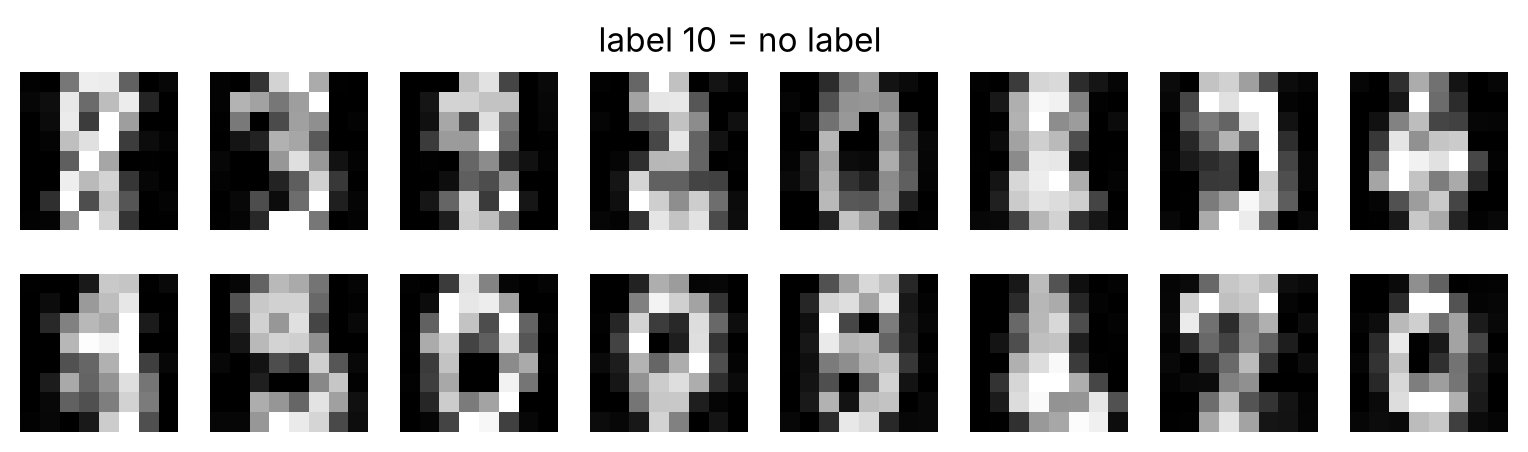

In [8]:
@torch.no_grad()
def draw(label, n=16, seed=0, noise=True):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 64, generator=g)
    lab = torch.full((n,), label)
    for t in reversed(range(T)):
        eps = model(x, torch.full((n,), t), lab)
        x = (x - beta[t] / (1 - abar[t]).sqrt() * eps) / (1 - beta[t]).sqrt()
        if t > 0 and noise:
            x += beta[t].sqrt() * torch.randn(n, 64, generator=g)
    return x

free = draw(10)
show_digits(free, title="label 10 = no label")

## 6. 指定要畫 7，再請另一個程式來認

裁判是用真的手寫數字訓練的邏輯迴歸分類器。

In [9]:
judge = LogisticRegression(max_iter=5000).fit(X.numpy(), y.numpy())
sevens = draw(7, n=100, seed=1)
print((judge.predict(sevens.clamp(-1, 1).numpy()) == 7).sum(), "/ 100")

99 / 100


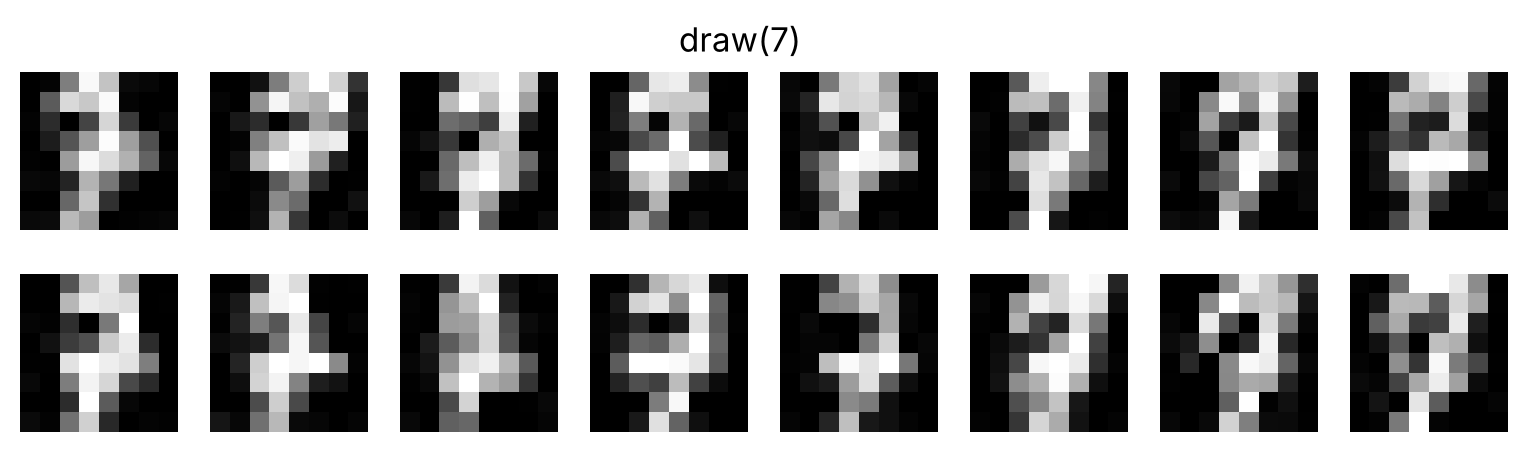

In [10]:
show_digits(sevens[:16], title="draw(7)")

## 7. 同一個種子，同一張圖

起點的雜訊和每一步加回的雜訊，都由隨機種子決定。

In [11]:
a, b, c = draw(3, n=4, seed=42), draw(3, n=4, seed=42), draw(3, n=4, seed=43)
print(torch.equal(a, b), torch.equal(a, c))

True False


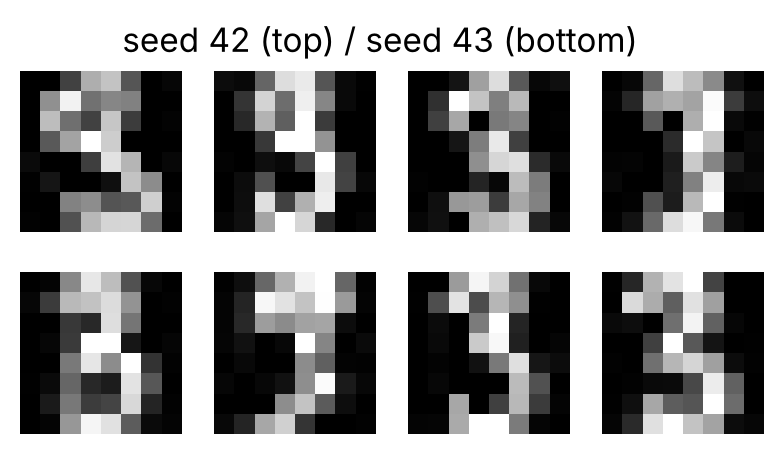

In [12]:
show_digits(torch.cat([a, c]), cols=4, title="seed 42 (top) / seed 43 (bottom)")

## 8. 故意做錯：不加新的雜訊

把每一步加回雜訊的那一行關掉（`noise=False`），16 張起點不同的雜訊會畫成什麼？
下面印的是 16 張之間的差異（每個像素的標準差，取平均）。

In [13]:
wrong = draw(10, noise=False)
print(free.std(dim=0).mean(), wrong.std(dim=0).mean())

tensor(0.3900) tensor(0.0095)


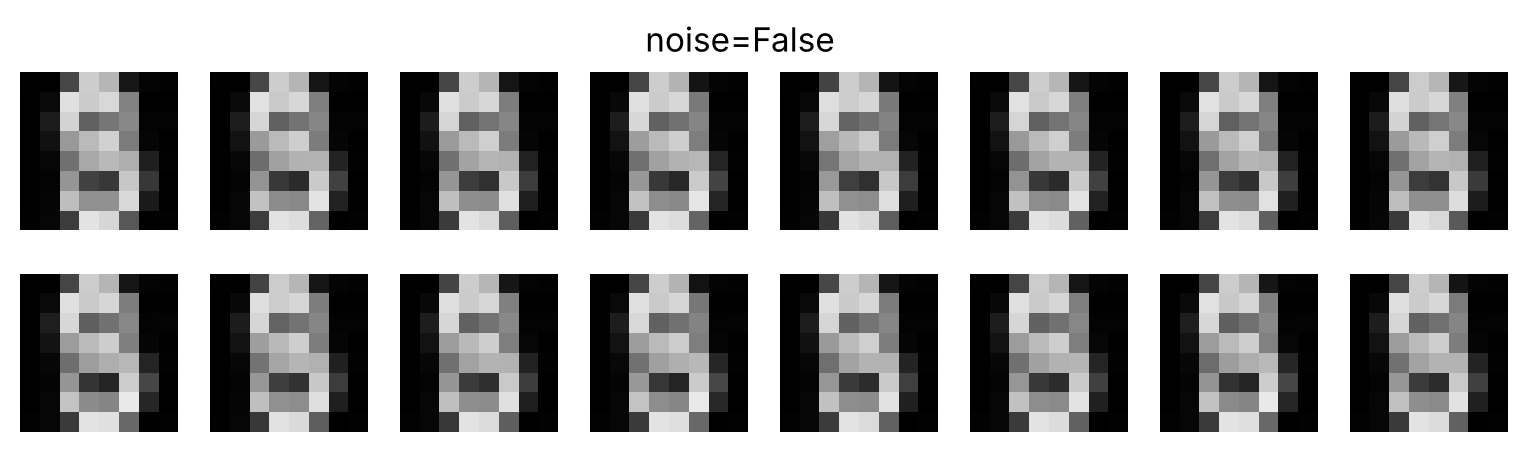

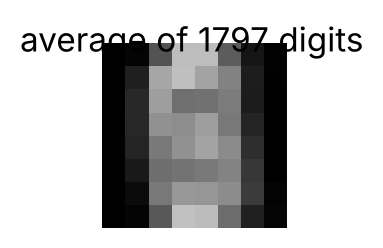

In [14]:
show_digits(wrong, title="noise=False")
show_digits(X.mean(dim=0, keepdim=True), cols=1, title="average of 1797 digits")

## 🧪 自己玩玩看

1. 把 `draw(7, ...)` 換成別的數字，或用 `draw(10, ...)` 不指定，多畫幾次。
2. 把訓練的 `range(20000)` 改成 `range(2000)`，模型只考兩千輪，畫出來會怎樣？
3. 換不同的 `seed`，看看同一個數字可以有幾種寫法。
4. 進階：只走一部分步數（例如 `reversed(range(0, T, 10))`）會發生什麼事？想想為什麼。

有問題歡迎到影片留言區問像素腦！